# Cross-cell-line Factor Comparison (96 features)

Each cell line was analyzed separately (`analysis_<line>.ipynb`): a few protein programs (latent protein-factors, each a weighted combination of the 96 features) summarize its average protein levels per drug and cell-cycle phase, together with how strongly each drug and phase activates each factor. This notebook asks which factors and drug responses are shared across the 8 cell lines.

Notation:
- Cell lines $\ell$ ($L = 8$), treatments $t$ (8), phases $j \in \{\mathrm{G1}, \mathrm{G2}, \mathrm{S}\}$ ($c = 3$), proteins $r$ ($p = 96$), latent protein-factors $f$ ($p_F = 4$).
- Per cell line: $\mathcal{X}^{(\ell)} \approx \mathcal{G}^{(\ell)} \times_1 T^{(\ell)} \times_2 C^{(\ell)} \times_3 P^{(\ell)}$, with protein loadings $P^{(\ell)} \in \mathbb{R}^{p \times p_F}$.
- Factor activity: $\mathcal{F}^{(\ell)} = \mathcal{G}^{(\ell)} \times_1 T^{(\ell)} \times_2 C^{(\ell)} \in \mathbb{R}^{8 \times c \times p_F}$; phase average $\bar{\mathcal{F}}^{(\ell)}_{tf} = \frac{1}{c} \sum_j \mathcal{F}^{(\ell)}_{tjf}$.

In [1]:
import pickle
import sys

sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from carve import CARVE, SpectralClustering

from cc_tensor import sign_align_protein_factors, cross_cellline_protein_factors, cross_cellline_treatment_factors, cross_cellline_protein_factors_by_treatment, cross_cellline_phase_profiles, cross_cellline_cell_activity, cross_cellline_protein_influence
from cc_tensor_viz import cross_cellline_embedding, cross_cellline_clustermap, cross_cellline_loading_violins, cross_cellline_treatment_violins, cross_cellline_cluster_violins, cross_cellline_cluster_heatmap

/Users/kaiwycik/.pyenv/versions/3.13.3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load results:

Load the factors fitted in each per-cell-line notebook.

1. For each $\ell$: load the fitted `CCTensor` from `results/cct_<line>.pkl`.

In [2]:
CELL_LINES = ["134", "231", "44PE", "453", "BCK4", "MCF10A", "MCF7", "T47D"]

cct_dict = {}
for name in CELL_LINES:
    with open(f"results/cct_{name}.pkl", "rb") as f:
        cct_dict[name] = pickle.load(f)


### 1.1 Sign alignment of the protein factors:

A factor and its mirror image (all protein weights and activities negated) describe the same biology, and each cell line's fit picks one of the two arbitrarily. We flip factors where needed so that a factor points the same way in every cell line; each line's fitted data are unchanged.

For each factor $f$:

1. $V_f \leftarrow [P^{(1)}_{:,f}, \dots, P^{(L)}_{:,f}] \in \mathbb{R}^{p \times L}$.
2. $\mathbf{v}_f \leftarrow$ leading left singular vector of $V_f$, oriented so that $\sum_\ell \mathbf{v}_f^\top P^{(\ell)}_{:,f} > 0$.
3. $s_{\ell f} \leftarrow \operatorname{sign}(\mathbf{v}_f^\top P^{(\ell)}_{:,f})$.
4. $P^{(\ell)}_{:,f} \leftarrow s_{\ell f} P^{(\ell)}_{:,f}$ and $\mathcal{G}^{(\ell)}_{:,:,f} \leftarrow s_{\ell f}\, \mathcal{G}^{(\ell)}_{:,:,f}$; $\hat{\mathcal{X}}^{(\ell)}$ is unchanged.

Table: $s_{\ell f}$ ($-1$ = flipped). Alignment fixes signs only; whether factor $f$ is the same program in every line is shown by the clustermap in 2.3.

In [3]:
cct_dict, flips = sign_align_protein_factors(cct_dict)
flips

,Factor 1,Factor 2,Factor 3,Factor 4
134,1,1,1,-1
231,-1,-1,-1,-1
44PE,1,1,-1,1
453,1,-1,-1,1
BCK4,1,-1,1,-1
MCF10A,1,-1,-1,1
MCF7,1,1,1,1
T47D,1,-1,1,1


## 2. Protein factors across cell lines:

Each factor is a set of 96 feature weights: proteins with the same sign move together when the factor is active, proteins with opposite signs move in opposite directions. We collect these weights from all cell lines to compare factors between lines.

1. For each $(\ell, f)$: row $\mathbf{x}_{\ell f} \leftarrow P^{(\ell)}_{:,f} \in \mathbb{R}^{p}$.
2. $X_P \leftarrow$ all rows, $X_P \in \mathbb{R}^{L p_F \times p}$ ($32 \times 96$).

In [4]:
protein_factor_df = cross_cellline_protein_factors(cct_dict)
print(f"Protein factor matrix: {protein_factor_df.shape}")
protein_factor_df.head(8)

Protein factor matrix: (32, 96)


nuc_53BP1  nuc_AurB  nuc_bCat  nuc_CDC25c  nuc_CDH1  \
cell_line factor                                                          
134       Factor 1  -0.063028 -0.114231 -0.131575   -0.092408 -0.088805   
          Factor 2   0.146378 -0.134250  0.075537    0.071719 -0.044822   
          Factor 3   0.109495  0.057973  0.121859    0.100271  0.029305   
          Factor 4   0.205214  0.047794  0.020177   -0.127466  0.065757   
231       Factor 1  -0.095391 -0.070692 -0.127706   -0.111823 -0.137623   
          Factor 2  -0.080969 -0.142842  0.093101    0.085894  0.031619   
          Factor 3  -0.121471  0.169355 -0.010546    0.004942  0.030652   
          Factor 4   0.094869  0.029801  0.056110    0.092709 -0.111394   

                    nuc_CDK2  nuc_CDK4  nuc_CDK6  nuc_CDT1  nuc_cMYC  ...  \
cell_line factor                                                      ...   
134       Factor 1 -0.113467 -0.067538 -0.105631 -0.005042 -0.022001  ...   
          Factor 2 -0.072821  0.136657  0.139221  0.148787  0.153756  ...   
          Factor 3  0.080732  0.045034  0.043330  0.066721 -0.177886  ...   
          Factor 4  0.015678  0.167674 -0.032569 -0.098721 -0.008571  ...   
231       Factor 1 -0.030804 -0.050024 -0.077463  0.023199 -0.029692  ...   
          Factor 2 -0.195419 -0.138077 -0.124322 -0.004559 -0.107935  ...   
          Factor 3 -0.051400 -0.186650 -0.187745 -0.164226 -0.152587  ...   
          Factor 4  0.138861  0.140555  0.085590 -0.267371 -0.200883  ...   

                    cyto_pERK  cyto_pH2AX  cyto_PH3  cyto_Plk1  cyto_pp130  \
cell_line factor                                                             
134       Factor 1  -0.103938   -0.122668 -0.112294  -0.107100   -0.081873   
          Factor 2  -0.057869    0.073402 -0.093802  -0.129861    0.056582   
          Factor 3   0.007462   -0.063871 -0.124359   0.058014   -0.090561   
          Factor 4  -0.275351   -0.093514  0.023305   0.055230   -0.257154   
231       Factor 1  -0.114904   -0.047117 -0.107157  -0.077437   -0.143639   
          Factor 2  -0.097799   -0.166106  0.091569  -0.078726    0.037864   
          Factor 3  -0.071918    0.060326  0.086612   0.191661   -0.012767   
          Factor 4  -0.047612   -0.138300  0.071785  -0.138184   -0.034603   

                     cyto_PR  cyto_pS6  cyto_SKP2  cyto_wee1  cyto_YAP1  
cell_line factor                                                         
134       Factor 1 -0.137551 -0.101972  -0.125994  -0.114055  -0.072782  
          Factor 2  0.054287 -0.070687  -0.086824  -0.098864   0.030340  
          Factor 3 -0.095573 -0.091284   0.059797  -0.081766   0.235064  
          Factor 4  0.035676 -0.011697   0.015298   0.047273  -0.071144  
231       Factor 1 -0.142209  0.033596  -0.061383  -0.135428  -0.140908  
          Factor 2  0.000760 -0.176740  -0.133254   0.000731   0.047578  
          Factor 3 -0.052500 -0.022288   0.136469   0.042354  -0.063263  
          Factor 4 -0.039351 -0.004639   0.124182   0.032731  -0.009118  

[8 rows x 96 columns]

### 2.1 PCA:

Each point is one factor from one cell line, placed so that factors with similar protein weights sit close together. If a factor is shared by all lines, its 8 points (one color) form a tight group.

1. $Z \leftarrow \mathrm{PCA}_2(X_P)$.
2. Scatter $Z$, one point per $(\ell, f)$: color $= f$, marker $= \ell$.

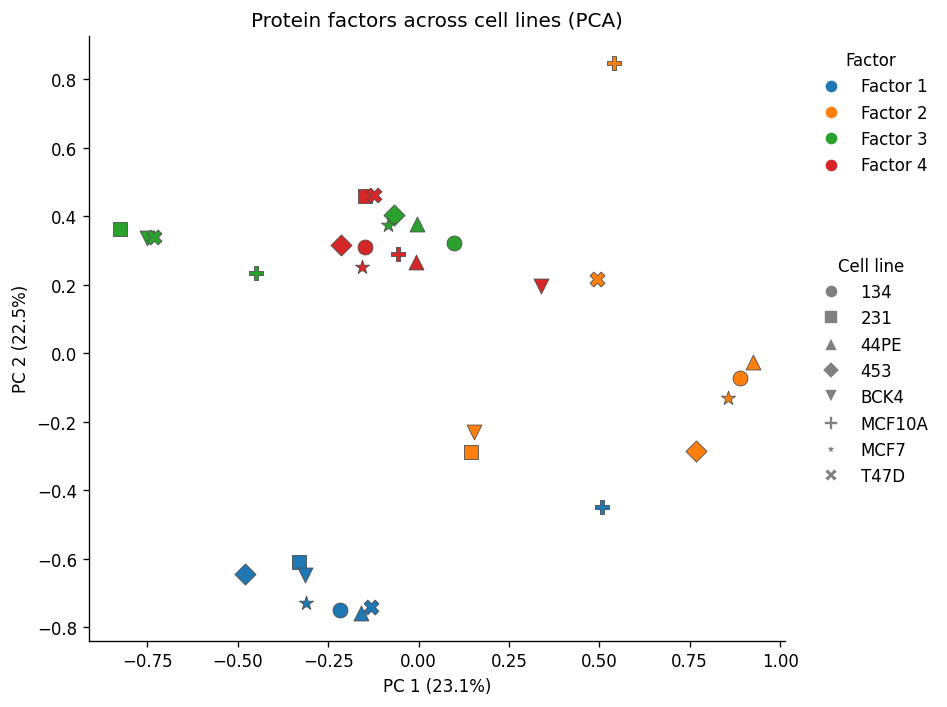

In [5]:
cross_cellline_embedding(
    protein_factor_df, method="pca",
    title="Protein factors across cell lines (PCA)"
);

### 2.2 UMAP:

The same comparison with a nonlinear map that keeps close neighbors together; tight groups are meaningful, distances between groups are not.

As 2.1 with $Z \leftarrow \mathrm{UMAP}_2(X_P)$.

/Users/kaiwycik/.pyenv/versions/3.13.3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


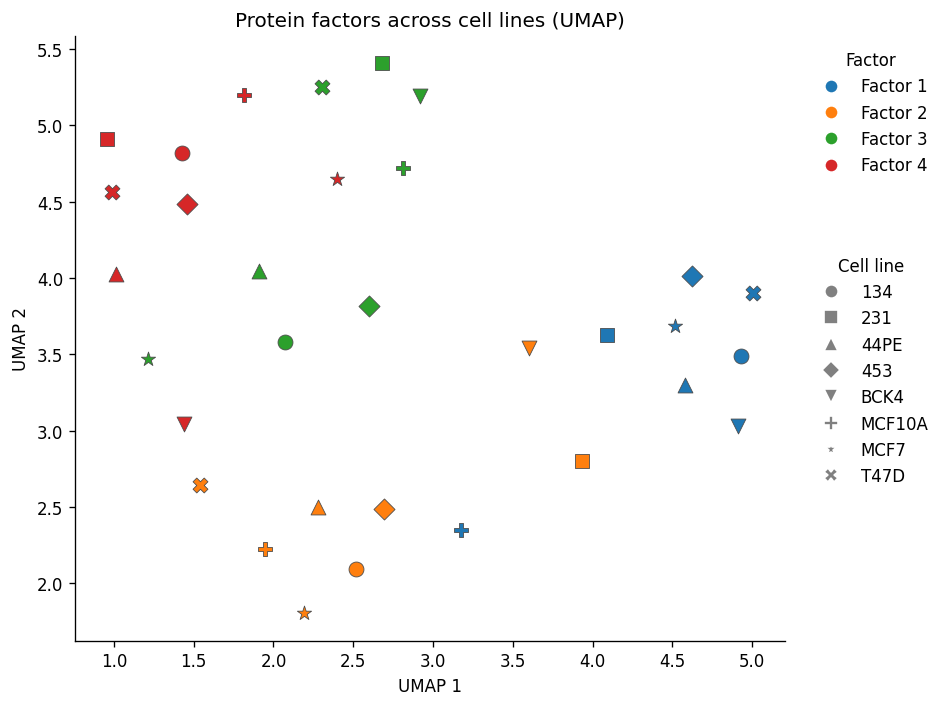

In [6]:
cross_cellline_embedding(
    protein_factor_df, method="umap",
    title="Protein factors across cell lines (UMAP)"
);

### 2.3 Cosine-similarity clustermap:

Each square is the similarity of two factors' protein weights, from 1 (same proteins, same directions) through 0 (unrelated) to -1 (same proteins, opposite directions). Red blocks are factors that recur across cell lines.

1. $S_{ab} \leftarrow \cos(\mathbf{x}_a, \mathbf{x}_b)$ for all pairs of rows of $X_P$.
2. $d_{ab} \leftarrow (1 - S_{ab}) / 2$; average-linkage clustering on $d$.
3. Heatmap of $S$, rows and columns in dendrogram order, annotated with $S_{ab}$.

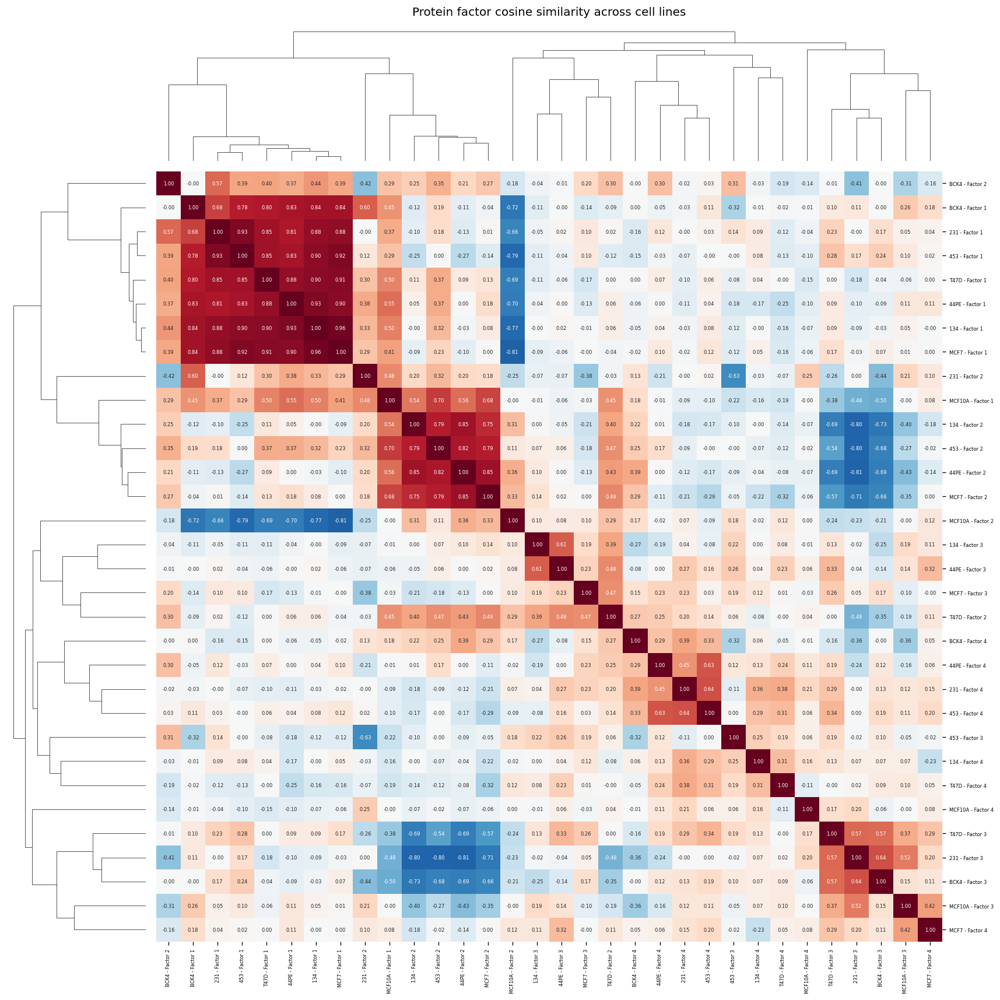

In [7]:
cross_cellline_clustermap(
    protein_factor_df,
    title="Protein factor cosine similarity across cell lines"
);

### 2.4 Loadings per protein:

For each protein, the spread of its weight on each factor across the 8 cell lines. A narrow violin away from zero means the protein plays the same role in that factor in every line.

1. For each protein $r$ and factor $f$: violin of $\{P^{(\ell)}_{rf}\}_{\ell=1}^{L}$ (aligned loadings, 8 values); color $= f$.
2. Points $=$ individual cell lines; dashed lines $=$ quartiles, long dashes $=$ median.

Pooling assumes factor $f$ is the same program in every line; check its block in 2.3.

With 96 features the plot is split into four panels: nuclear features (two halves) and cytoplasmic features (two halves).

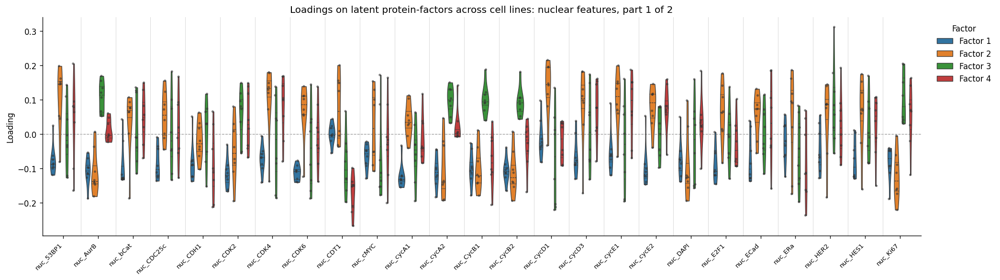

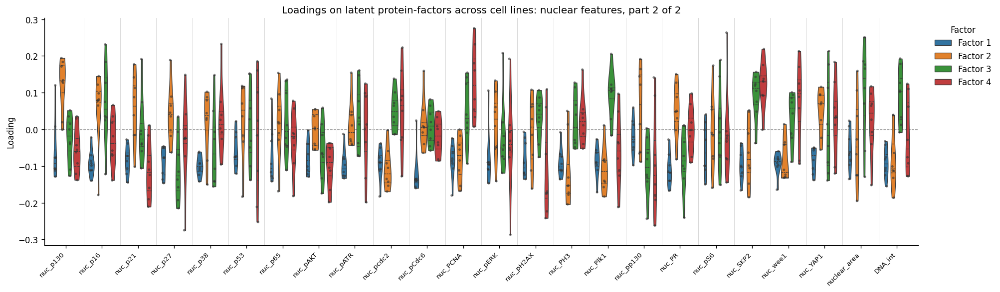

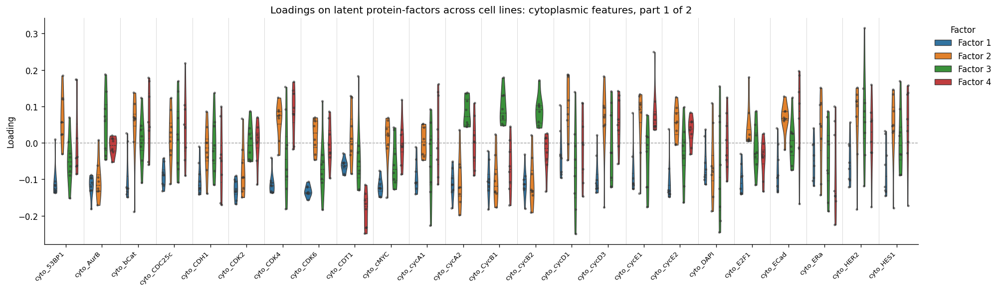

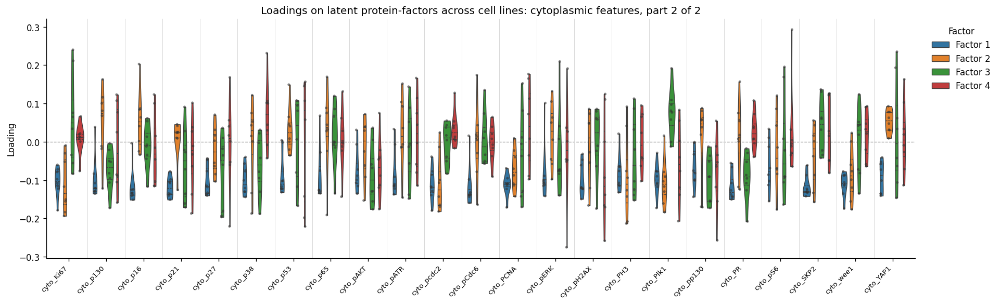

In [8]:
nuclear = [p for p in protein_factor_df.columns if not p.startswith("cyto_")]
cyto = [p for p in protein_factor_df.columns if p.startswith("cyto_")]

for name, cols in [("nuclear", nuclear), ("cytoplasmic", cyto)]:
    for i, part in enumerate(np.array_split(cols, 2)):
        cross_cellline_loading_violins(
            protein_factor_df[list(part)], factors=["Factor 1", "Factor 2", "Factor 3", "Factor 4"],
            title=f"Loadings on latent protein-factors across cell lines: {name} features, part {i + 1} of 2"
        );

## 3. Protein factors by treatment:

A factor's protein weights are scaled by how strongly a drug engages the factor in that cell line (averaged over G1, G2 and S). The result is the protein change, relative to the cell line's average over all drugs and phases, that the drug produces through this factor.

1. For each $(\ell, t, f)$: row $\mathbf{y}_{\ell t f} \leftarrow \bar{\mathcal{F}}^{(\ell)}_{tf}\, P^{(\ell)}_{:,f} \in \mathbb{R}^{p}$.
2. $Y \leftarrow$ all rows, $Y \in \mathbb{R}^{L \cdot 8 \cdot p_F \times p}$ ($256 \times 96$).

$\mathbf{y}_{\ell t f}$ does not depend on the sign of $P^{(\ell)}_{:,f}$.

In [9]:
protein_factor_by_treatment_df = cross_cellline_protein_factors_by_treatment(cct_dict)
print(f"Protein factor by treatment matrix: {protein_factor_by_treatment_df.shape}")

protein_factor_by_treatment_df.head(8)

Protein factor by treatment matrix: (256, 96)


nuc_53BP1  nuc_AurB  nuc_bCat  nuc_CDC25c  \
cell_line treatment factor                                                
134       CVT-313   Factor 1  -0.217418 -0.394044 -0.453872   -0.318763   
                    Factor 2  -0.264062  0.242183 -0.136267   -0.129379   
                    Factor 3  -0.174380 -0.092327 -0.194070   -0.159690   
                    Factor 4   0.384640  0.089582  0.037819   -0.238915   
          Control   Factor 1   0.107580  0.194977  0.224580    0.157727   
                    Factor 2  -0.077776  0.071332 -0.040136   -0.038107   
                    Factor 3  -0.268231 -0.142017 -0.298517   -0.245635   
                    Factor 4   0.059877  0.013945  0.005887   -0.037192   

                              nuc_CDH1  nuc_CDK2  nuc_CDK4  nuc_CDK6  \
cell_line treatment factor                                             
134       CVT-313   Factor 1 -0.306335 -0.391407 -0.232975 -0.364377   
                    Factor 2  0.080858  0.131368 -0.246526 -0.251151   
                    Factor 3 -0.046671 -0.128572 -0.071720 -0.069006   
                    Factor 4  0.123252  0.029385  0.314277 -0.061046   
          Control   Factor 1  0.151578  0.193672  0.115278  0.180297   
                    Factor 2  0.023816  0.038693 -0.072611 -0.073974   
                    Factor 3 -0.071789 -0.197768 -0.110319 -0.106144   
                    Factor 4  0.019187  0.004574  0.048924 -0.009503   

                              nuc_CDT1  nuc_cMYC  ...  cyto_pERK  cyto_pH2AX  \
cell_line treatment factor                        ...                          
134       CVT-313   Factor 1 -0.017391 -0.075895  ...  -0.358537   -0.423148   
                    Factor 2 -0.268409 -0.277372  ...   0.104393   -0.132416   
                    Factor 3 -0.106258  0.283298  ...  -0.011883    0.101720   
                    Factor 4 -0.185036 -0.016066  ...  -0.516102   -0.175277   
          Control   Factor 1  0.008605  0.037553  ...   0.177408    0.209378   
                    Factor 2 -0.079057 -0.081697  ...   0.030748   -0.039002   
                    Factor 3 -0.163446  0.435768  ...  -0.018279    0.156466   
                    Factor 4 -0.028805 -0.002501  ...  -0.080342   -0.027286   

                              cyto_PH3  cyto_Plk1  cyto_pp130   cyto_PR  \
cell_line treatment factor                                                
134       CVT-313   Factor 1 -0.387362  -0.369445   -0.282424 -0.474487   
                    Factor 2  0.169217   0.234267   -0.102072 -0.097933   
                    Factor 3  0.198051  -0.092393    0.144226  0.152208   
                    Factor 4  0.043681   0.103519   -0.481994  0.066868   
          Control   Factor 1  0.191670   0.182805    0.139746  0.234781   
                    Factor 2  0.049841   0.069001   -0.030064 -0.028845   
                    Factor 3  0.304641  -0.142118    0.221848  0.234125   
                    Factor 4  0.006800   0.016115   -0.075033  0.010409   

                              cyto_pS6  cyto_SKP2  cyto_wee1  cyto_YAP1  
cell_line treatment factor                                               
134       CVT-313   Factor 1 -0.351756  -0.434619  -0.393436  -0.251063  
                    Factor 2  0.127518   0.156628   0.178348  -0.054732  
                    Factor 3  0.145377  -0.095231   0.130220  -0.374358  
                    Factor 4 -0.021924   0.028673   0.088606  -0.133348  
          Control   Factor 1  0.174052   0.215054   0.194676   0.124228  
                    Factor 2  0.037559   0.046133   0.052530  -0.016121  
                    Factor 3  0.223619  -0.146483   0.200303  -0.575835  
                    Factor 4 -0.003413   0.004464   0.013793  -0.020758  

[8 rows x 96 columns]

### 3.1 PCA:

Each point is one drug-factor combination in one cell line, labeled by drug; points close together are conditions that shift the proteins in a similar way.

1. $Z \leftarrow \mathrm{PCA}_2(Y)$.
2. Scatter $Z$, one point per $(\ell, t, f)$: color $= f$, marker $= \ell$, text $= t$.

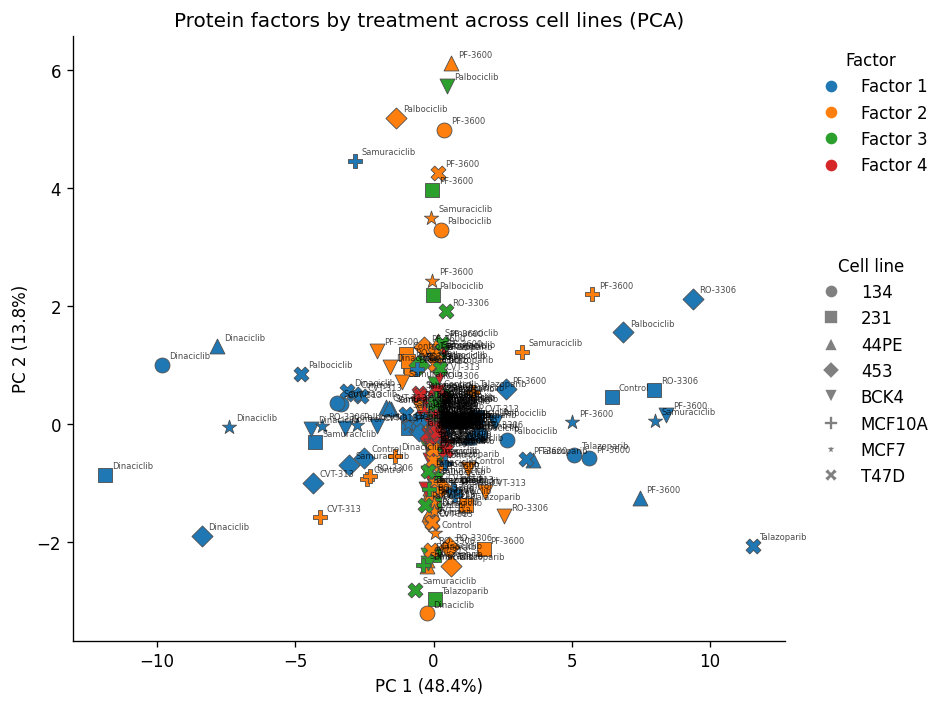

In [10]:
cross_cellline_embedding(
    protein_factor_by_treatment_df, method="pca",
    title="Protein factors by treatment across cell lines (PCA)"
);

### 3.2 t-SNE:

The same comparison with a nonlinear map that emphasizes local groups; nearby labels share a protein response, distances between groups are not meaningful.

As 3.1 with $Z \leftarrow \mathrm{tSNE}_2(Y)$.

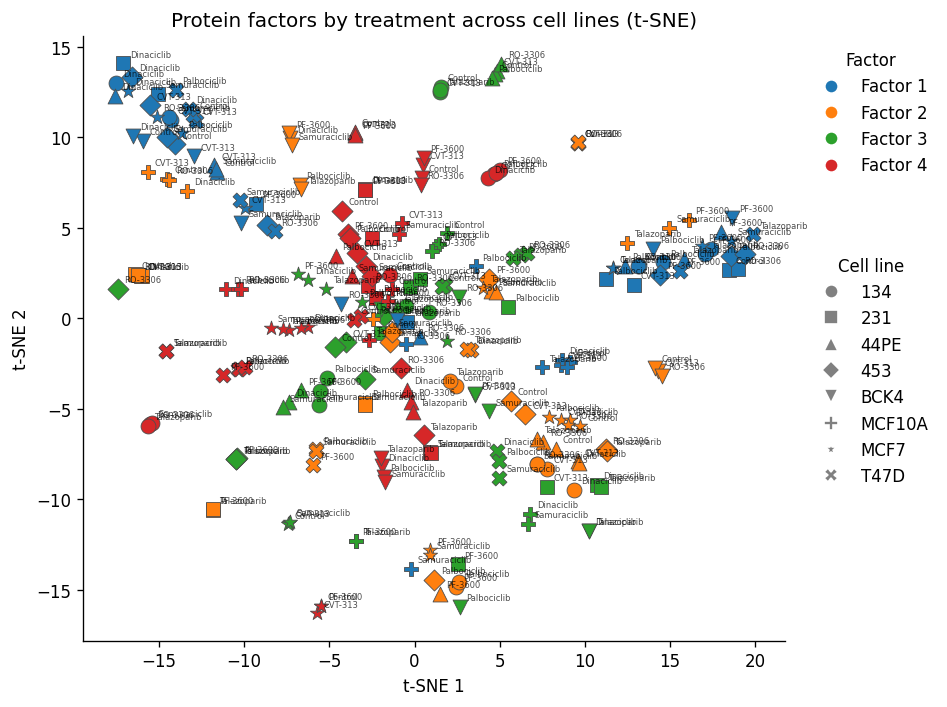

In [11]:
cross_cellline_embedding(
    protein_factor_by_treatment_df, method="tsne",
    title="Protein factors by treatment across cell lines (t-SNE)"
);

### 3.3 PCA without Factors 1 and 4:

The same comparison as 3.1, restricted to Factors 2 and 3.

As 3.1 on the rows of $Y$ with $f \in \{2, 3\}$.

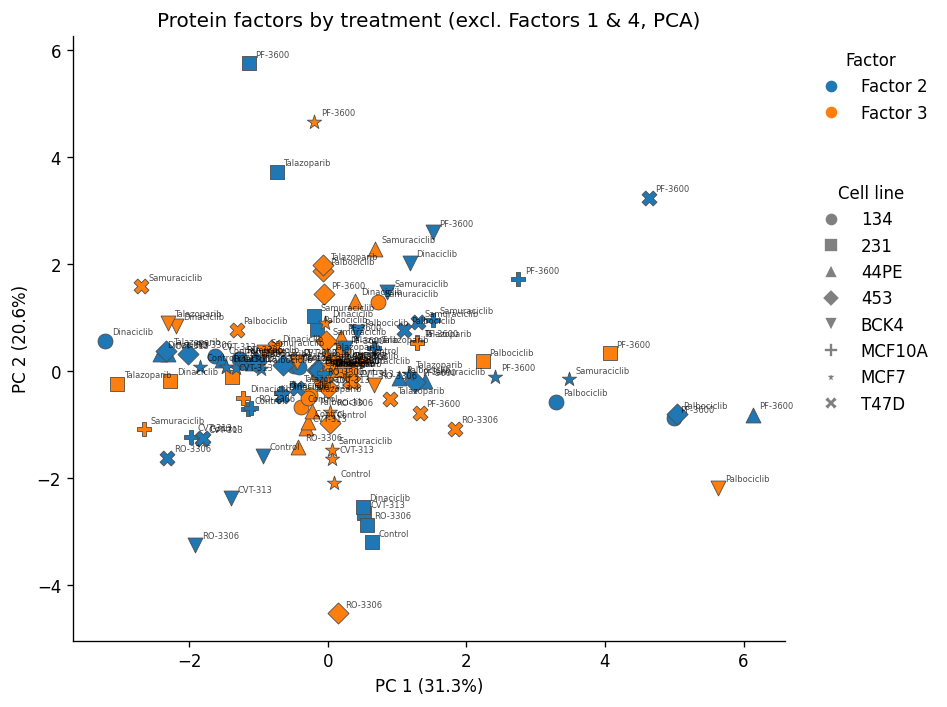

In [12]:
cross_cellline_embedding(
    protein_factor_by_treatment_df, method="pca",
    exclude_factors=["Factor 1", "Factor 4"],
    title="Protein factors by treatment (excl. Factors 1 & 4, PCA)"
);

### 3.4 t-SNE without Factors 1 and 4:

The same comparison as 3.2, restricted to Factors 2 and 3.

As 3.2 on the rows of $Y$ with $f \in \{2, 3\}$.

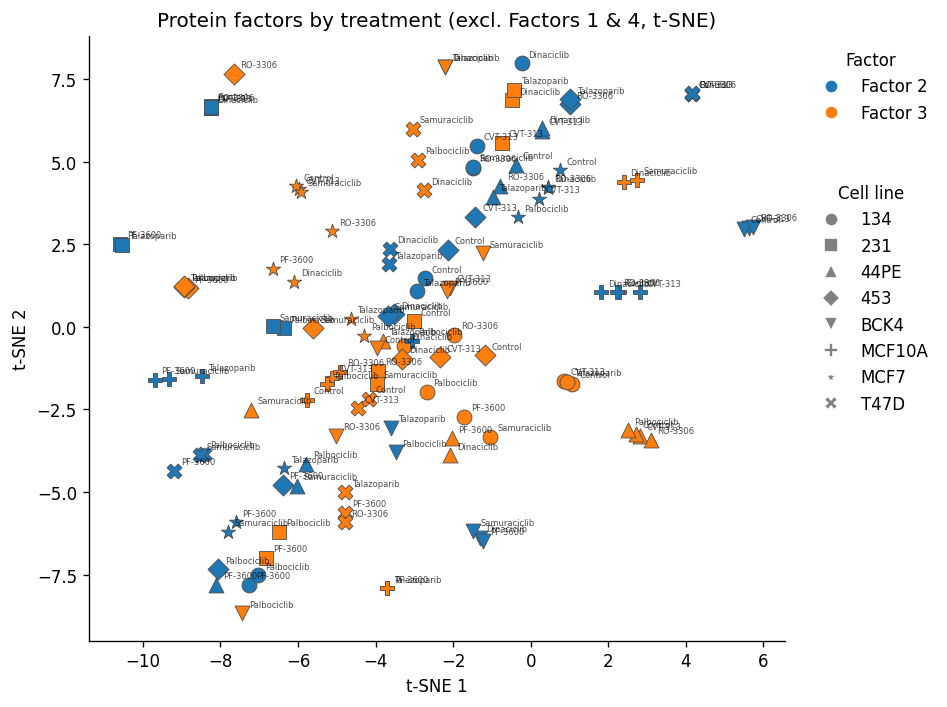

In [13]:
cross_cellline_embedding(
    protein_factor_by_treatment_df, method="tsne",
    exclude_factors=["Factor 1", "Factor 4"],
    title="Protein factors by treatment (excl. Factors 1 & 4, t-SNE)"
);

## 4. Phase profiles:

For each drug in each cell line: how active a factor is in G1, G2 and S. Two conditions with the same profile engage the factor with the same timing through the cell cycle, possibly at different strengths.

1. For each $(\ell, t, f)$: row $\boldsymbol{\phi}_{\ell t f} \leftarrow \mathcal{F}^{(\ell)}_{t,:,f} \in \mathbb{R}^{c}$ (activity of $f$ in G1, G2, S).
2. $\Phi \leftarrow$ all rows ($256 \times 3$).

$\boldsymbol{\phi}_{\ell t f}$ flips with the sign of $P^{(\ell)}_{:,f}$, hence the alignment in 1.1.

In [14]:
phase_profiles_df = cross_cellline_phase_profiles(cct_dict)
print(f"Phase profiles matrix: {phase_profiles_df.shape}")
phase_profiles_df.head(8)

Phase profiles matrix: (256, 3)


G1        G2         S
cell_line treatment factor                                
134       CVT-313   Factor 1  7.560336 -1.684440  4.472706
                    Factor 2  1.399441 -4.404750 -2.406622
                    Factor 3 -0.981620 -1.710392 -2.085730
                    Factor 4  0.834893  2.721483  2.066641
          Control   Factor 1  4.465180 -8.597457 -0.988313
                    Factor 2  2.846151 -3.594596 -0.845577
                    Factor 3 -1.660977 -2.483473 -3.204644
                    Factor 4 -0.357797  0.963765  0.269374

### 4.1 Factor 1 clustermap:

Similarity of the Factor 1 phase profiles of all drug-by-cell-line conditions, ignoring overall strength: 1 = same timing, -1 = opposite timing. The side bars show whether a block is formed by one drug or by one cell line.

1. Rows: $\boldsymbol{\phi}_{\ell t 1}$ for all $(\ell, t)$ ($64 \times 3$).
2. $S_{ab} \leftarrow \cos(\boldsymbol{\phi}_a, \boldsymbol{\phi}_b)$; $d_{ab} \leftarrow (1 - S_{ab}) / 2$; average linkage.
3. Heatmap of $S$ in dendrogram order; side bars: cell line, treatment.

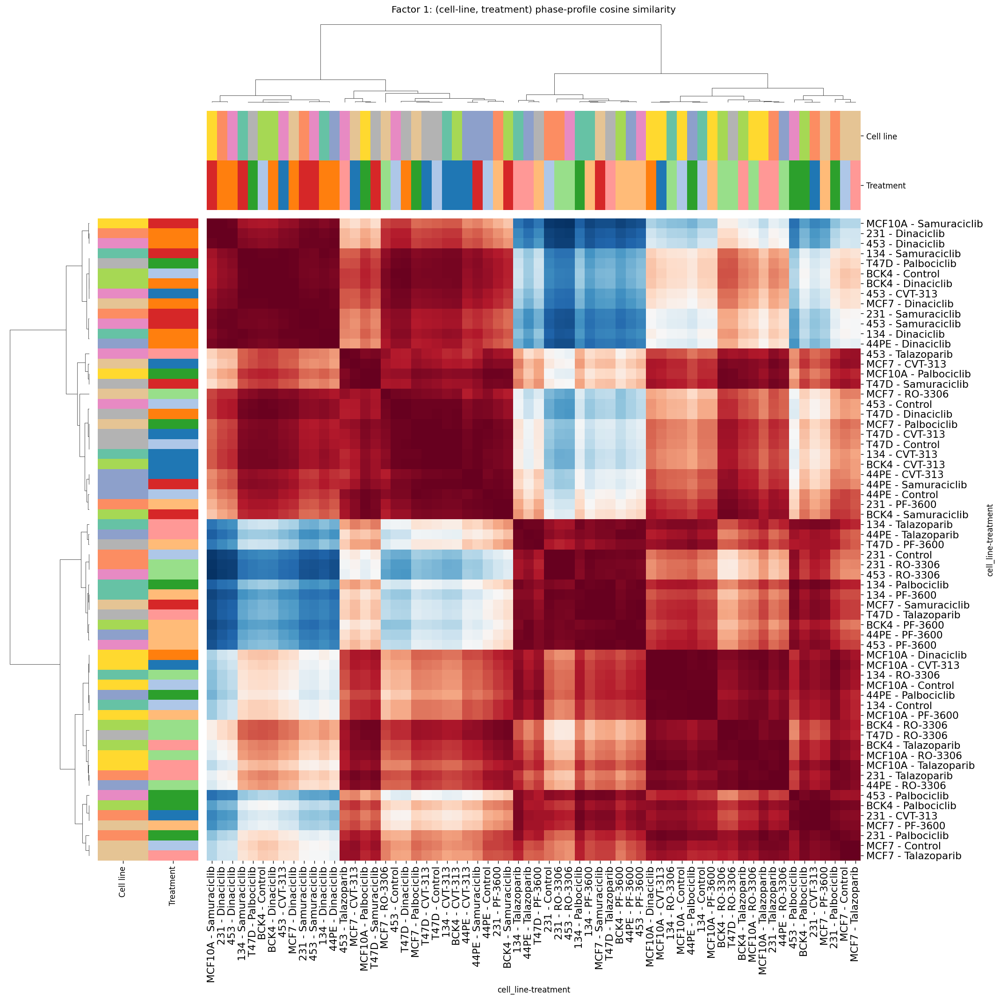

In [15]:
cross_cellline_clustermap(
    phase_profiles_df.xs("Factor 1", level="factor"),
    annotate=False,
    title="Factor 1: (cell-line, treatment) phase-profile cosine similarity",
);

### 4.2 Factor 2 clustermap:

The same comparison as 4.1 for Factor 2.

As 4.1 with $f = 2$.

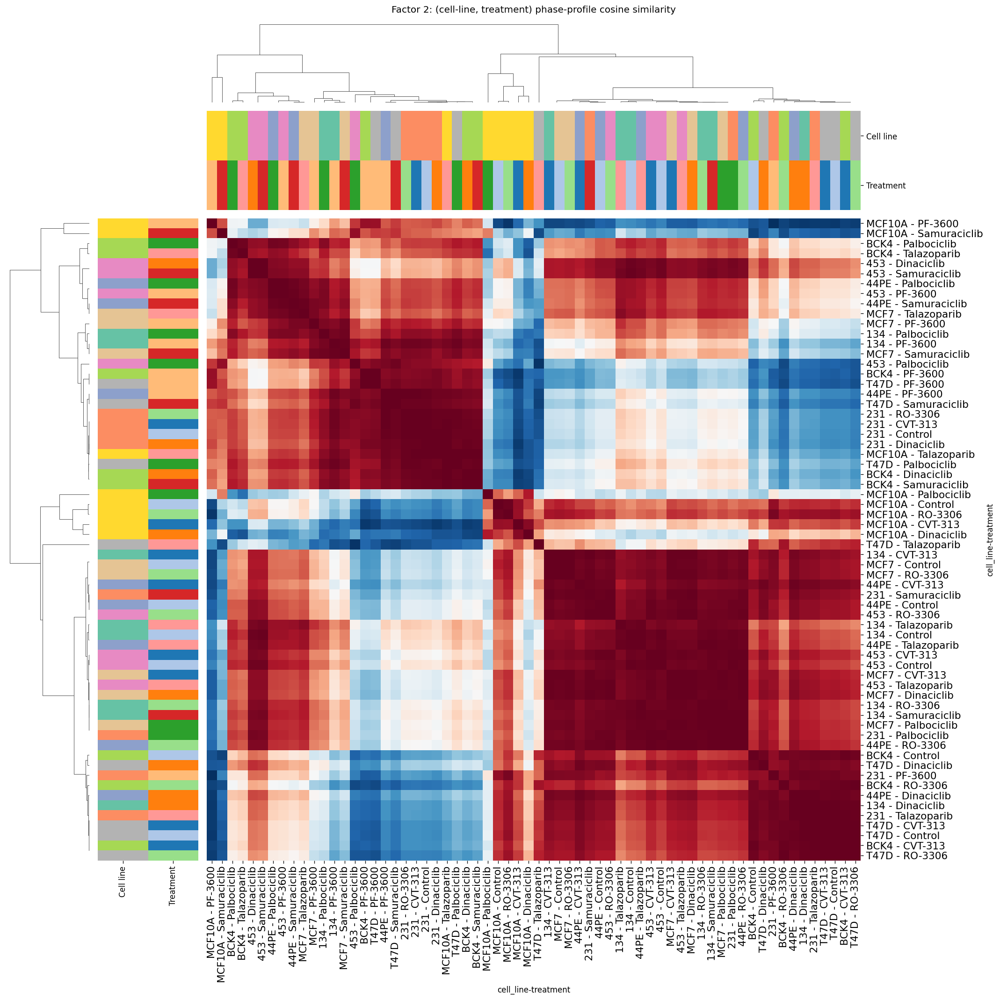

In [16]:
cross_cellline_clustermap(
    phase_profiles_df.xs("Factor 2", level="factor"),
    annotate=False,
    title="Factor 2: (cell-line, treatment) phase-profile cosine similarity",
);

### 4.3 Single-cell factor activity by treatment:

How strongly each drug engages each factor in individual G1, G2 and S cells, pooled over the 8 cell lines; 0 is the cell line's average over all drugs and phases. For each drug, every cell line contributes the same number of cells, so large lines do not dominate.

1. For each $\ell$: $\mathbf{m}^{(\ell)}, \mathbf{s}^{(\ell)} \leftarrow$ per-protein mean and standard deviation of the $8 \times c$ pseudobulk means used to build $\mathcal{X}^{(\ell)}$.
2. For each cell of line $\ell$ with protein vector $\mathbf{x}$: $a_f \leftarrow \big((\mathbf{x} - \mathbf{m}^{(\ell)}) / \mathbf{s}^{(\ell)}\big)^\top P^{(\ell)}_{:,f}$ (aligned $P^{(\ell)}$).
3. For each drug $t$: $n_t \leftarrow$ number of cells of the smallest line under $t$; draw $n_t$ cells of $t$ at random from each line.
4. For each $(t, j, f)$: violin of $a_f$ over the drawn cells of drug $t$ in phase $j$, restricted to its central 98% (1st to 99th percentile); x $= t$, color $= j$, one panel per $f$. Dashed lines $=$ quartiles, long dashes $=$ median.

The mean of $a_f$ over all cells of line $\ell$, drug $t$ and phase $j$ is exactly $\mathcal{F}^{(\ell)}_{tjf}$, so the violins show the cell-to-cell spread behind the phase profiles $\Phi$. The trimming in step 4 removes rare extreme cells ($|a_f|$ up to about 1000) that would otherwise flatten the violins.

Cells per cell line: {'CVT-313': 2661, 'Control': 645, 'Dinaciclib': 716, 'PF-3600': 2248, 'Palbociclib': 230, 'RO-3306': 2099, 'Samuraciclib': 660, 'Talazoparib': 2082}


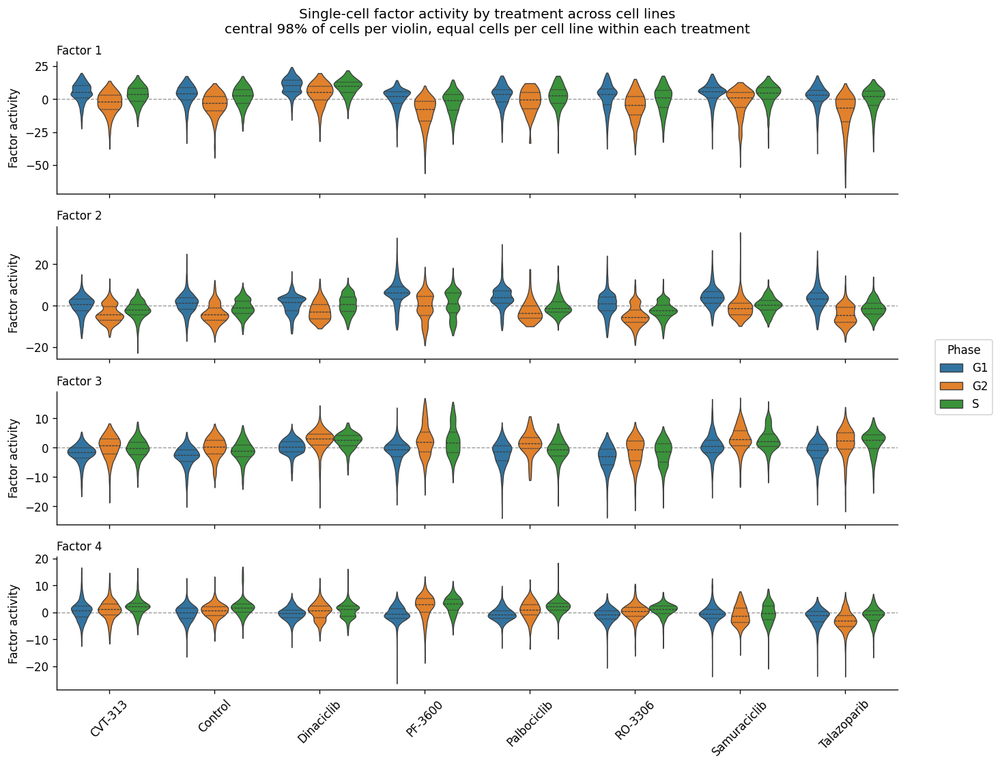

In [17]:
cell_activity_df = cross_cellline_cell_activity(cct_dict)
print("Cells per cell line:", cell_activity_df.groupby("treatment").size().floordiv(len(CELL_LINES)).to_dict())

cross_cellline_treatment_violins(
    cell_activity_df,
    title="Single-cell factor activity by treatment across cell lines"
);

### 4.4 Single-cell factor activity by treatment, all phases:

The same cells as in 4.3 without splitting by phase. Each phase contributes in proportion to its share of a drug's cells, so a violin describes the treated population as it is, for example mostly G1 cells under a drug that arrests cells in G1.

1. Same cells and $a_f$ as in 4.3.
2. For each $(t, f)$: violin of $a_f$ over all drawn cells of drug $t$, central 98%; x $= t$, color $= f$, one panel per $f$.

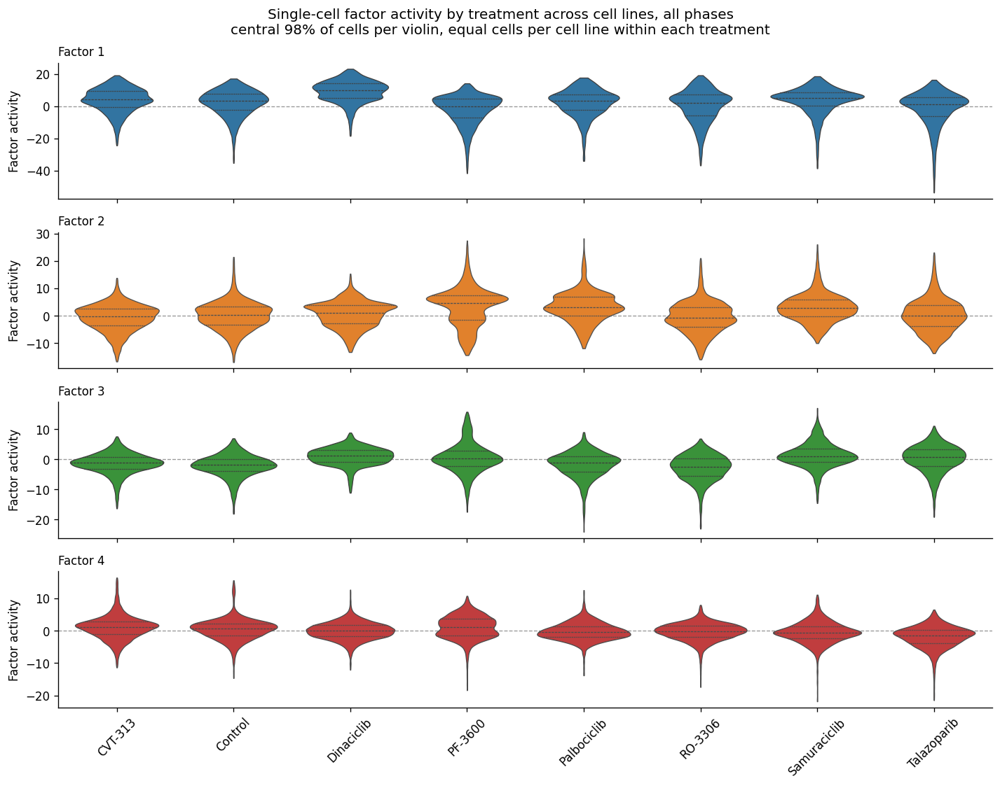

In [18]:
cross_cellline_treatment_violins(
    cell_activity_df, pool_phases=True,
    title="Single-cell factor activity by treatment across cell lines, all phases"
);

## 5. CARVE clustering of phase profiles:

The protein change a factor produces under one drug, in one cell line and one phase: its protein weights scaled by its activity there. Averaging over the three phases gives the quantities of section 3.

Protein influence, used by the heatmaps and violins below:

1. For each $(\ell, t, j, f)$: row $\mathbf{q}_{\ell t j f} \leftarrow \mathcal{F}^{(\ell)}_{tjf}\, P^{(\ell)}_{:,f} \in \mathbb{R}^{p}$.
2. Averaging over $j$ gives $\mathbf{y}_{\ell t f}$ (section 3).

In [19]:
protein_influence_df = cross_cellline_protein_influence(cct_dict)
print(f"Protein influence matrix: {protein_influence_df.shape}")

protein_influence_df.head(8)

Protein influence matrix: (768, 96)


nuc_53BP1  nuc_AurB  nuc_bCat  nuc_CDC25c  \
cell_line treatment phase factor                                                
134       CVT-313   G1    Factor 1  -0.476514 -0.863625 -0.994750   -0.698632   
                          Factor 2   0.204847 -0.187874  0.105709    0.100367   
                          Factor 3  -0.107483 -0.056908 -0.119619   -0.098428   
                          Factor 4   0.171332  0.039903  0.016846   -0.106421   
                    G2    Factor 1   0.106167  0.192415  0.221630    0.155655   
                          Factor 2  -0.644758  0.591336 -0.332721   -0.315904   
                          Factor 3  -0.187280 -0.099157 -0.208426   -0.171503   
                          Factor 4   0.558486  0.130071  0.054912   -0.346897   

                                    nuc_CDH1  nuc_CDK2  nuc_CDK4  nuc_CDK6  \
cell_line treatment phase factor                                             
134       CVT-313   G1    Factor 1 -0.671394 -0.857846 -0.510611 -0.798604   
                          Factor 2 -0.062726 -0.101909  0.191243  0.194831   
                          Factor 3 -0.028767 -0.079248 -0.044206 -0.042533   
                          Factor 4  0.054900  0.013089  0.139990 -0.027192   
                    G2    Factor 1  0.149586  0.191128  0.113764  0.177929   
                          Factor 2  0.197430  0.320760 -0.601939 -0.613232   
                          Factor 3 -0.050124 -0.138083 -0.077025 -0.074111   
                          Factor 4  0.178958  0.042667  0.456321 -0.088637   

                                    nuc_CDT1  nuc_cMYC  ...  cyto_pERK  \
cell_line treatment phase factor                        ...              
134       CVT-313   G1    Factor 1 -0.038117 -0.166338  ...  -0.785804   
                          Factor 2  0.208219  0.215172  ...  -0.080984   
                          Factor 3 -0.065495  0.174617  ...  -0.007325   
                          Factor 4 -0.082421 -0.007156  ...  -0.229889   
                    G2    Factor 1  0.008492  0.037060  ...   0.175077   
                          Factor 2 -0.655371 -0.677255  ...   0.254896   
                          Factor 3 -0.114119  0.304255  ...  -0.012762   
                          Factor 4 -0.268667 -0.023327  ...  -0.749364   

                                    cyto_pH2AX  cyto_PH3  cyto_Plk1  \
cell_line treatment phase factor                                      
134       CVT-313   G1    Factor 1   -0.927412 -0.848980  -0.809711   
                          Factor 2    0.102722 -0.131271  -0.181733   
                          Factor 3    0.062698  0.122073  -0.056948   
                          Factor 4   -0.078074  0.019457   0.046111   
                    G2    Factor 1    0.206627  0.189152   0.180403   
                          Factor 2   -0.323318  0.413176   0.572007   
                          Factor 3    0.109245  0.212702  -0.099227   
                          Factor 4   -0.254497  0.063424   0.150306   

                                    cyto_pp130   cyto_PR  cyto_pS6  cyto_SKP2  \
cell_line treatment phase factor                                                
134       CVT-313   G1    Factor 1   -0.618988 -1.039932 -0.770944  -0.952554   
                          Factor 2    0.079183  0.075972 -0.098923  -0.121505   
                          Factor 3    0.088897  0.093816  0.089606  -0.058697   
                          Factor 4   -0.214696  0.029785 -0.009766   0.012772   
                    G2    Factor 1    0.137910  0.231696  0.171766   0.212229   
                          Factor 2   -0.249228 -0.239122  0.311360   0.382437   
                          Factor 3    0.154896  0.163467  0.156132  -0.102276   
                          Factor 4   -0.699841  0.097090 -0.031833   0.041633   

                                    cyto_wee1  cyto_YAP1  
cell_line treatment phase factor                          
134       CVT-313   G1    Factor 1  -0.862294  -0.550254  
    

We group the drug-by-cell-line conditions by the timing of a factor's activity across G1, G2 and S, ignoring overall strength. CARVE tries several clustering methods and numbers of groups on resampled data and keeps the largest number of groups that carries over to held-out data nearly as well as the best choice.

Clustering of factor $f$ (`run_carve`):

1. $\mathbf{x}_{\ell t} \leftarrow \boldsymbol{\phi}_{\ell t f} / \|\boldsymbol{\phi}_{\ell t f}\|$, so that $\|\mathbf{x}_a - \mathbf{x}_b\|^2 = 2\,(1 - \cos(\boldsymbol{\phi}_a, \boldsymbol{\phi}_b))$.
2. CARVE on the 64 points $\mathbf{x}_{\ell t}$: KMeans, Ward, self-tuning spectral (no feature scaling); $k = 2, \dots, 8$; 100 resamples.
3. $\hat{k} \leftarrow$ largest $k$ within one standard error of the best generalizability (ARI).
4. Labels $\leftarrow$ average-linkage cut of the consensus matrix at $\hat{k}$.

In [20]:
ks = list(range(2, 9))
carve_grids = [
    (KMeans, {"n_clusters": ks}),
    (AgglomerativeClustering, {"n_clusters": ks, "linkage": ["ward"]}),
    (SpectralClustering, {"n_clusters": ks, "affinity": ["self_tuning"], "scale": [False]}),
]


def run_carve(factor, measure="generalizability", rule="1se"):
    """CARVE on the unit-normalized phase profiles of one factor; returns (carve, k, labels)."""
    X = phase_profiles_df.xs(factor, level="factor")
    X = X.div(np.linalg.norm(X.values, axis=1), axis=0)

    carve = CARVE(estimator_param_grids=carve_grids, n_resamples=100, random_state=0, n_jobs=4).fit(X)
    k = carve.get_k(measure=measure, rule=rule)
    labels = pd.Series(carve.get_labels(measure=measure, rule=rule), index=X.index, name="cluster")
    print(f"{factor}: selected k = {k}")
    return carve, k, labels


def plot_carve_diagnostics(carve, factor, measure="generalizability", rule="1se"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    carve.plot_metric_over_n_clusters(measure="stability", rule=rule, ax=axes[0])
    carve.plot_metric_over_n_clusters(measure="generalizability", rule=rule, ax=axes[1])
    fig.suptitle(factor)
    fig.tight_layout()
    carve.plot_consensus_matrix(measure=measure, rule=rule, title=f"{factor}: consensus matrix")

### 5.1 Factor 1:

In [21]:
carve_f1, k_f1, labels_f1 = run_carve("Factor 1")

Factor 1: selected k = 2


How reproducible the grouping is for each number of groups (left: across resamples; right: on held-out data), and how often each pair of conditions landed in the same group (below). Sharp blocks in the lower plot mean well-separated groups.

Diagnostics:

1. Left: stability vs. $k$, one line per estimator configuration, error bars $\pm 1$ SE; dashed line $=$ $k$ the 1-SE rule picks on this metric.
2. Right: the same for generalizability; its dashed line is $\hat{k}$.
3. Below: consensus matrix $M$ of the selected configuration, $M_{ab} =$ fraction of resamples containing $a$ and $b$ in which they share a cluster; top band $=$ labels.

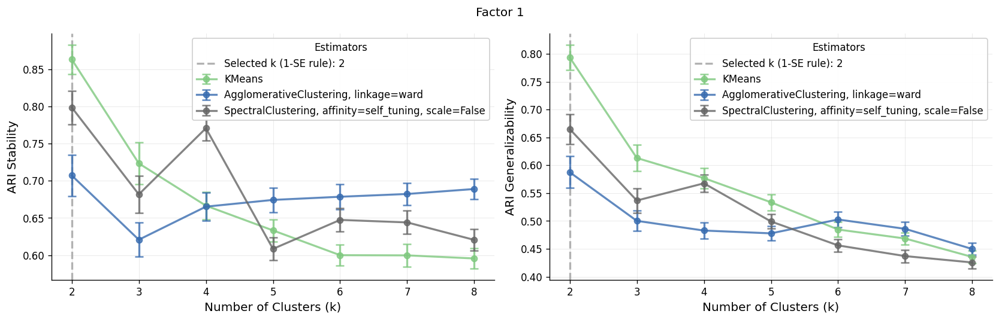

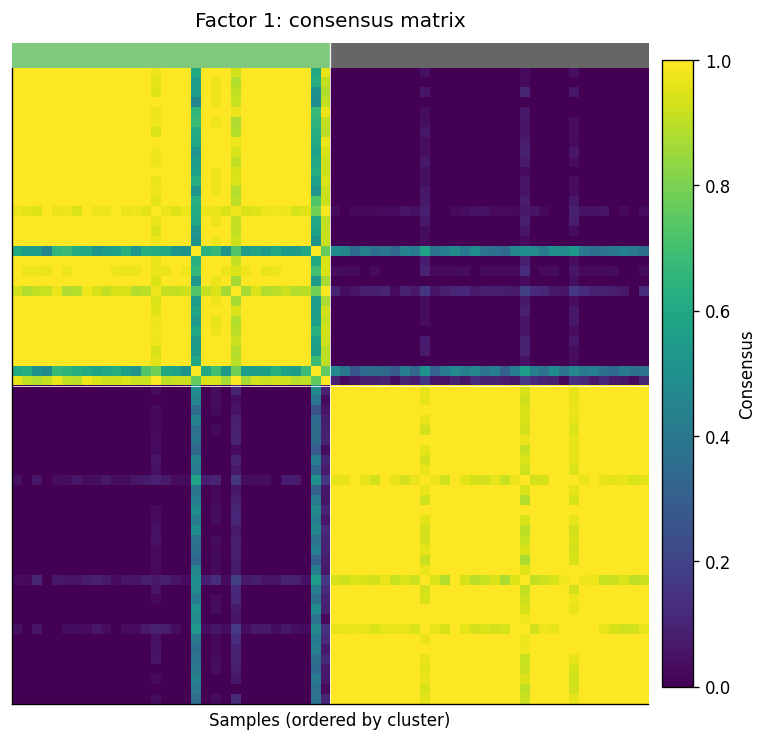

In [22]:
plot_carve_diagnostics(carve_f1, "Factor 1")

The group of each drug in each cell line. A column with a single group means the drug acts with the same timing in all lines; a row with a single group means the line responds with the same timing to all drugs.

Cluster membership: entry $(\ell, t) =$ cluster of $\boldsymbol{\phi}_{\ell t 1}$.

In [23]:
labels_f1.add(1).unstack("treatment")

treatment,CVT-313,Control,Dinaciclib,PF-3600,Palbociclib,RO-3306,Samuraciclib,Talazoparib
cell_line,,,,,,,,
134,1,2,1,2,2,2,1,2
231,2,2,1,1,2,2,1,2
44PE,1,1,1,2,2,2,1,2
453,1,1,1,2,2,2,1,1
BCK4,1,1,1,2,2,1,1,2
MCF10A,2,2,2,2,1,2,1,2
MCF7,1,2,1,2,1,1,2,2
T47D,1,1,1,2,1,1,1,2


The protein change each condition produces through Factor 1 (red = up, blue = down, relative to the cell line's average), grouped by the timing clusters. Within a group, conditions with similar protein changes are placed next to each other.

Phase-averaged protein influence by cluster:

1. Rows: $\mathbf{y}_{\ell t 1}$ for all $(\ell, t)$; columns: proteins.
2. Group rows by cluster $1, \dots, \hat{k}$ (white lines).
3. Within a cluster: rows in the leaf order of average-linkage clustering (Euclidean) of the $\mathbf{y}_{\ell t 1}$.
4. Side bars: cell line, treatment, cluster.

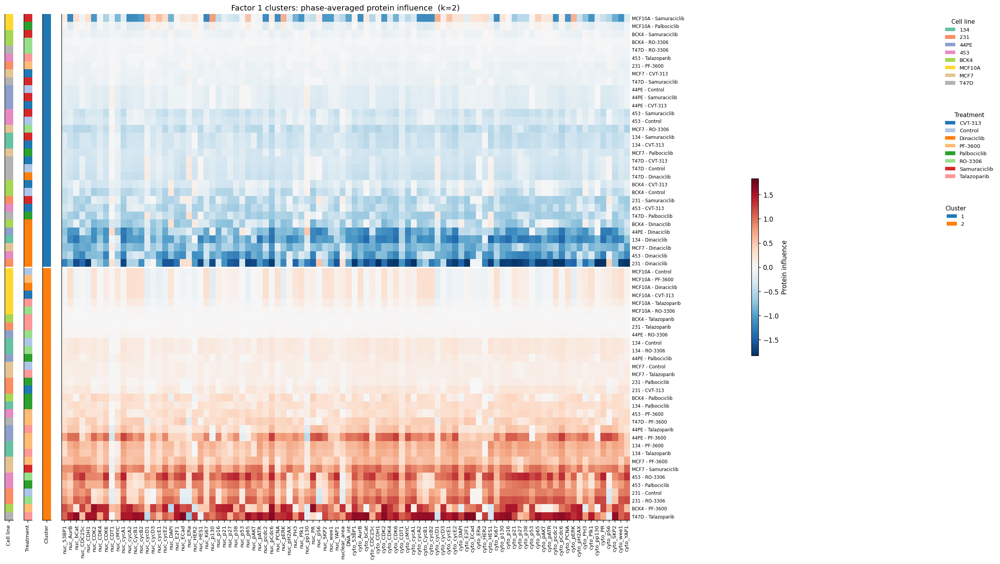

In [24]:
cross_cellline_cluster_heatmap(
    protein_factor_by_treatment_df.xs("Factor 1", level="factor"), labels_f1,
    title="Factor 1 clusters: phase-averaged protein influence",
);

For each protein, the distribution of its factor-driven changes within each timing cluster, pooled over conditions and phases and shown separately per factor. It shows which factors move which proteins in each cluster.

Protein influence by cluster, all factors:

1. For each protein $r$ (panel), cluster $m$ (x-axis) and factor $f'$ (color): violin of $\{q_{\ell t j f', r} : (\ell, t) \in m,\ j \in \{\mathrm{G1}, \mathrm{G2}, \mathrm{S}\}\}$.
2. Points $=$ individual values; dashed lines $=$ quartiles, long dashes $=$ median; grey number $= |m|$.
3. y-axis clipped to the 2nd-98th percentile of the panel.

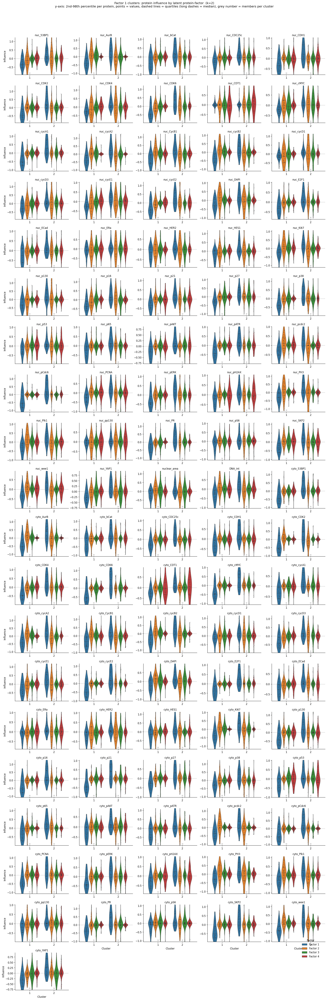

In [25]:
cross_cellline_cluster_violins(
    protein_influence_df, labels_f1,
    title="Factor 1 clusters: protein influence by latent protein-factor",
);

### 5.2 Factor 2:

As 5.1 with $f = 2$.

In [26]:
carve_f2, k_f2, labels_f2 = run_carve("Factor 2")

Factor 2: selected k = 2


Diagnostics for $f = 2$ (as in 5.1).

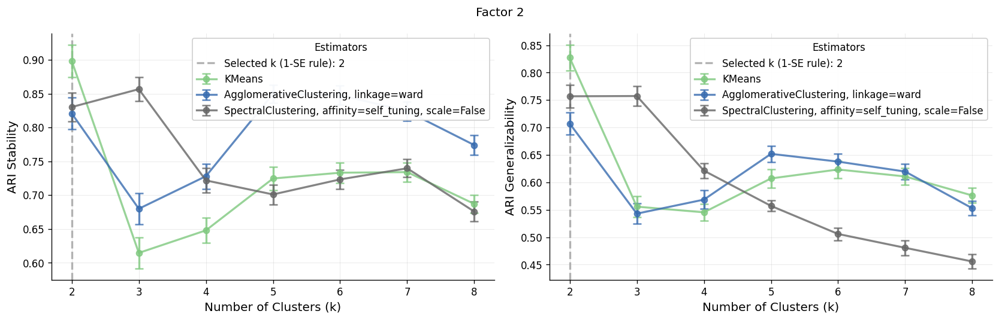

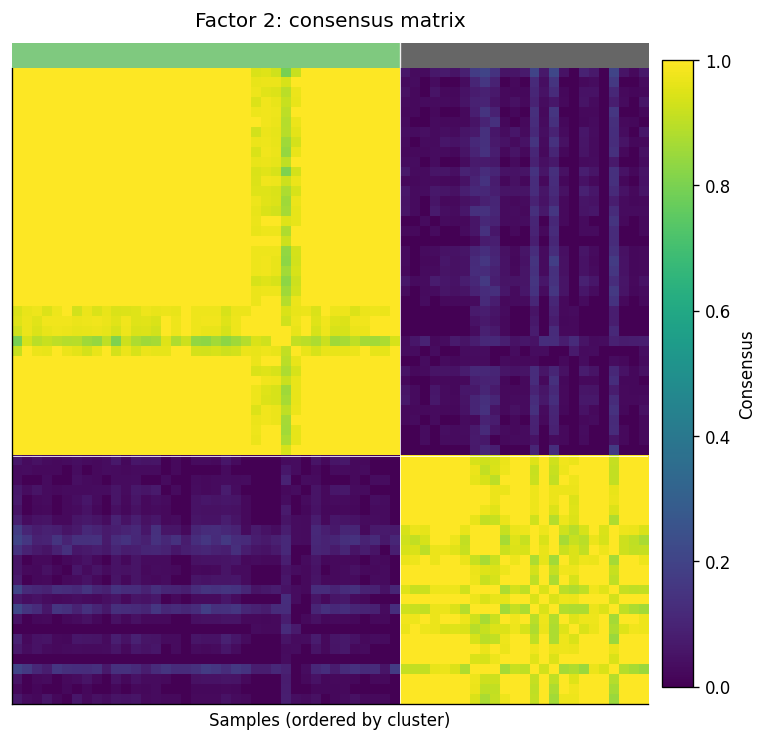

In [27]:
plot_carve_diagnostics(carve_f2, "Factor 2")

Cluster membership: entry $(\ell, t) =$ cluster of $\boldsymbol{\phi}_{\ell t 2}$.

In [28]:
labels_f2.add(1).unstack("treatment")

treatment,CVT-313,Control,Dinaciclib,PF-3600,Palbociclib,RO-3306,Samuraciclib,Talazoparib
cell_line,,,,,,,,
134,1,1,1,2,2,1,1,1
231,2,2,2,1,1,2,1,1
44PE,1,1,1,2,2,1,2,1
453,1,1,1,2,2,1,1,1
BCK4,1,1,2,2,2,1,2,2
MCF10A,1,1,1,2,1,1,2,2
MCF7,1,1,1,2,1,1,2,2
T47D,1,1,1,2,2,1,2,1


Heatmap as in 5.1, rows $\mathbf{y}_{\ell t 2}$.

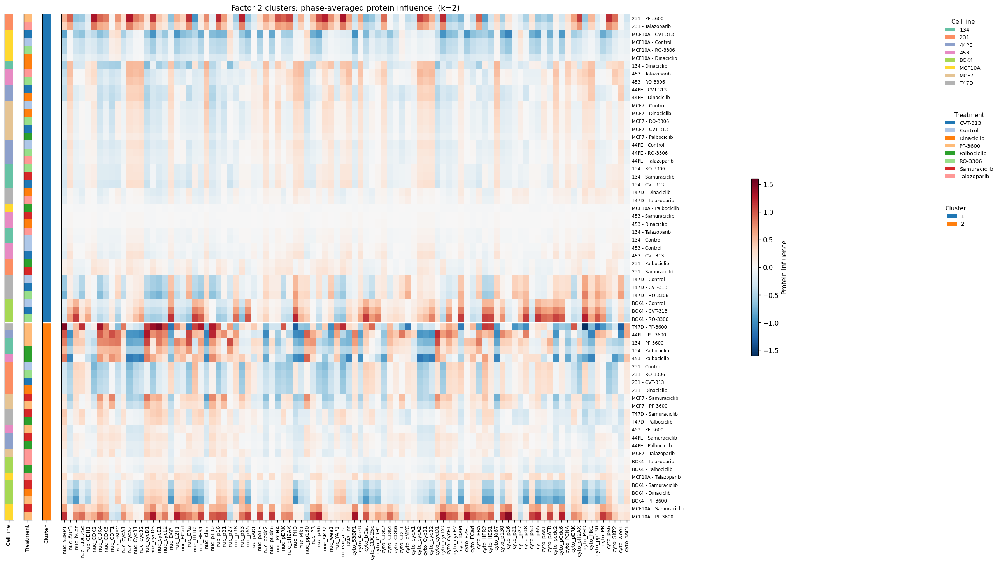

In [29]:
cross_cellline_cluster_heatmap(
    protein_factor_by_treatment_df.xs("Factor 2", level="factor"), labels_f2,
    title="Factor 2 clusters: phase-averaged protein influence",
);

Violins as in 5.1, clusters from $f = 2$.

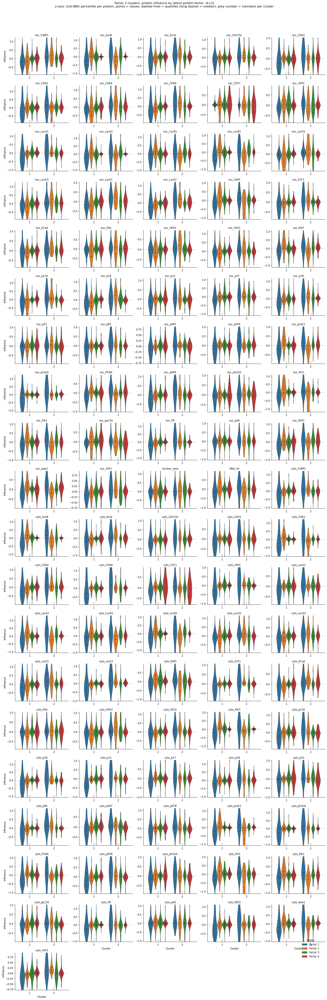

In [30]:
cross_cellline_cluster_violins(
    protein_influence_df, labels_f2,
    title="Factor 2 clusters: protein influence by latent protein-factor",
);

### 5.3 Factor 3:

As 5.1 with $f = 3$.

In [31]:
carve_f3, k_f3, labels_f3 = run_carve("Factor 3")

Factor 3: selected k = 3


Diagnostics for $f = 3$ (as in 5.1).

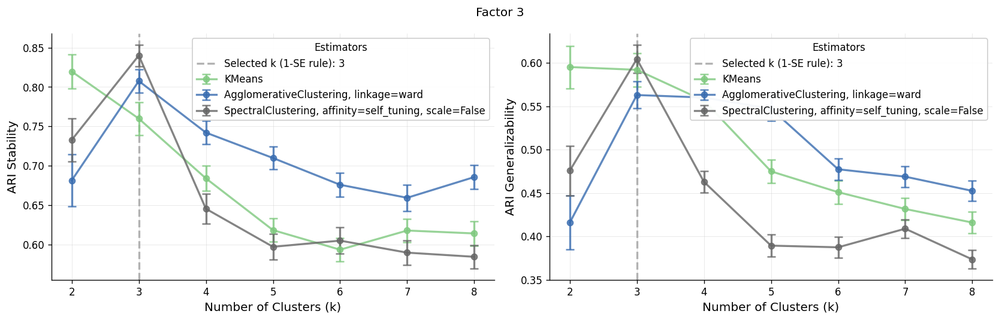

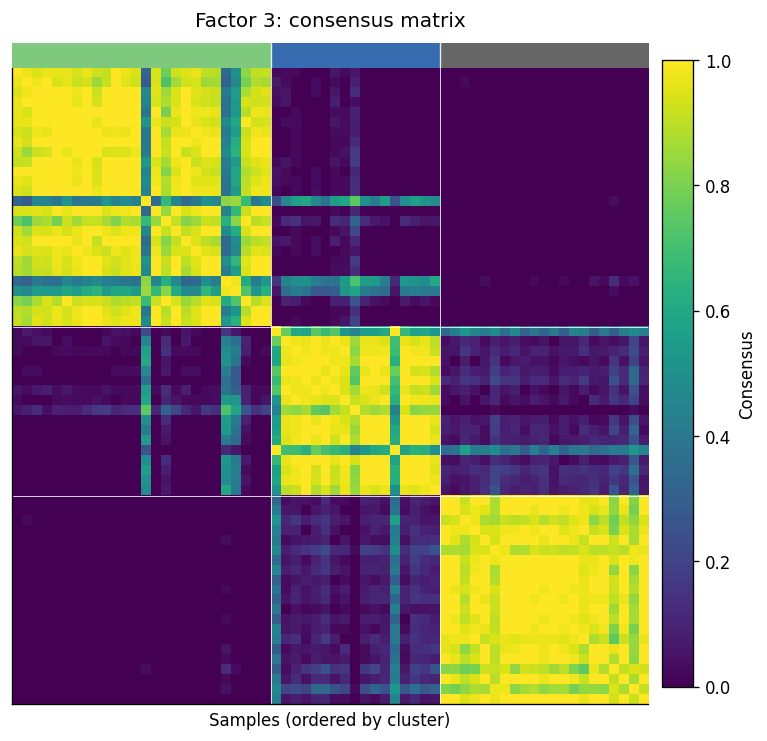

In [32]:
plot_carve_diagnostics(carve_f3, "Factor 3")

Cluster membership: entry $(\ell, t) =$ cluster of $\boldsymbol{\phi}_{\ell t 3}$.

In [33]:
labels_f3.add(1).unstack("treatment")

treatment,CVT-313,Control,Dinaciclib,PF-3600,Palbociclib,RO-3306,Samuraciclib,Talazoparib
cell_line,,,,,,,,
134,3,3,2,1,1,3,1,3
231,1,2,1,3,3,2,2,1
44PE,3,3,1,1,3,3,1,2
453,2,3,2,1,1,3,1,1
BCK4,1,2,1,2,3,2,1,1
MCF10A,2,2,1,3,2,2,1,3
MCF7,3,3,1,1,1,3,3,1
T47D,2,2,1,3,1,3,1,2


Heatmap as in 5.1, rows $\mathbf{y}_{\ell t 3}$.

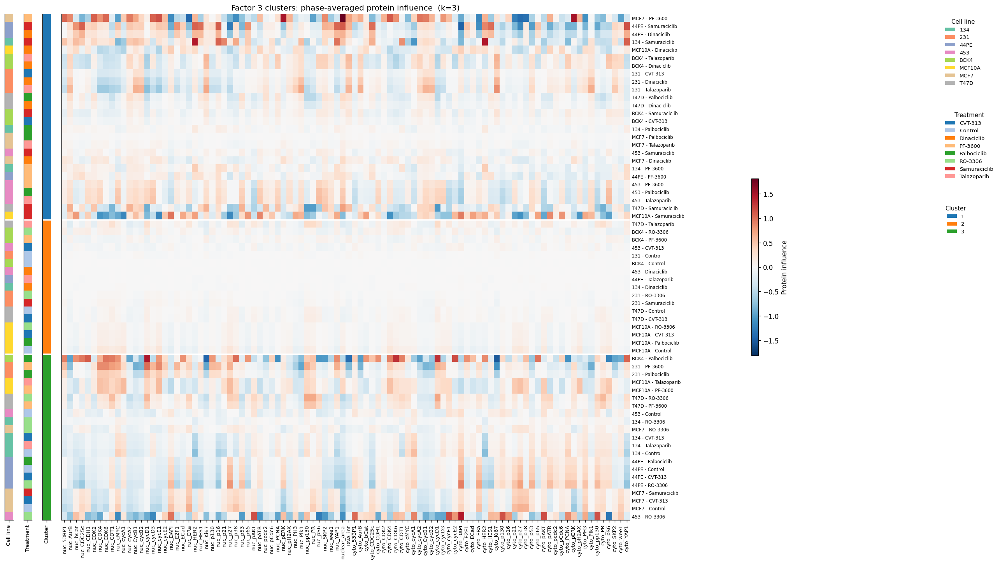

In [34]:
cross_cellline_cluster_heatmap(
    protein_factor_by_treatment_df.xs("Factor 3", level="factor"), labels_f3,
    title="Factor 3 clusters: phase-averaged protein influence",
);

### 5.4 Factor 4:

As 5.1 with $f = 4$.

In [35]:
carve_f4, k_f4, labels_f4 = run_carve("Factor 4")

Factor 4: selected k = 2


Diagnostics for $f = 4$ (as in 5.1).

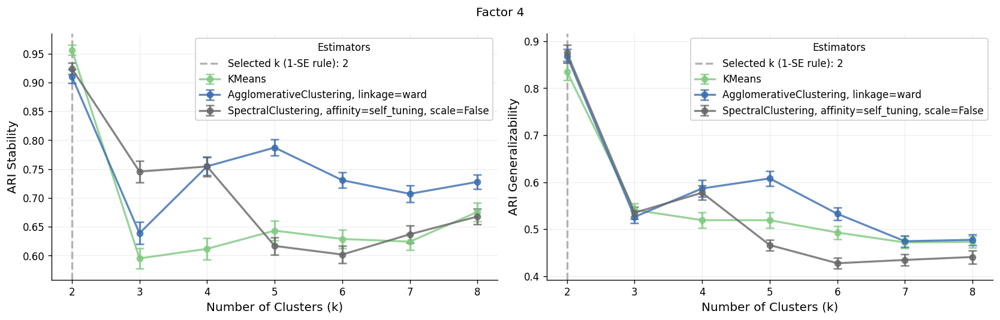

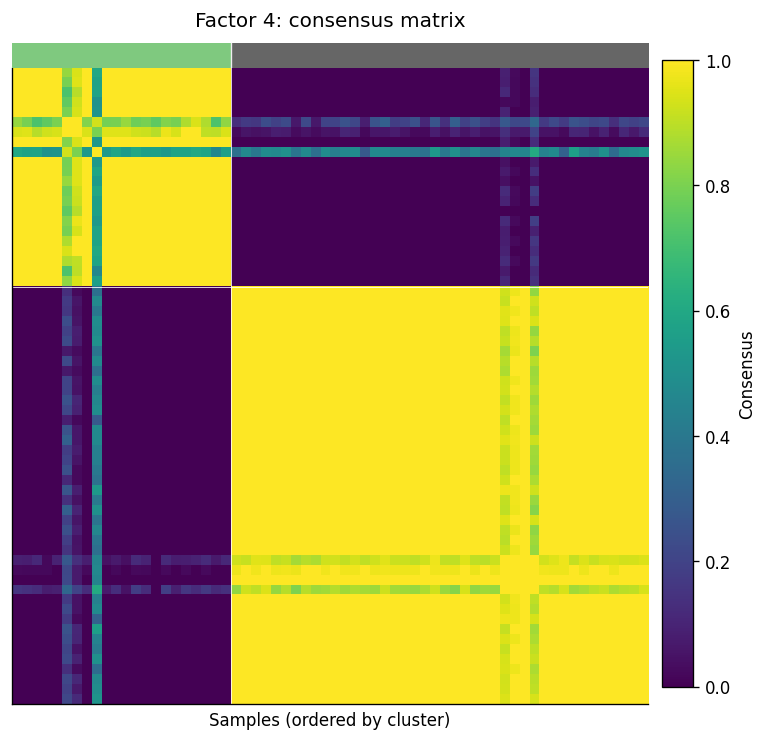

In [36]:
plot_carve_diagnostics(carve_f4, "Factor 4")

Cluster membership: entry $(\ell, t) =$ cluster of $\boldsymbol{\phi}_{\ell t 4}$.

In [37]:
labels_f4.add(1).unstack("treatment")

treatment,CVT-313,Control,Dinaciclib,PF-3600,Palbociclib,RO-3306,Samuraciclib,Talazoparib
cell_line,,,,,,,,
134,2,2,2,2,2,1,1,1
231,2,2,2,2,2,2,1,1
44PE,2,2,1,2,2,1,2,1
453,2,2,2,2,2,1,2,1
BCK4,2,2,1,2,1,2,1,1
MCF10A,2,2,1,2,1,1,2,2
MCF7,1,1,2,1,2,2,2,2
T47D,2,2,2,2,2,2,1,1


Heatmap as in 5.1, rows $\mathbf{y}_{\ell t 4}$.

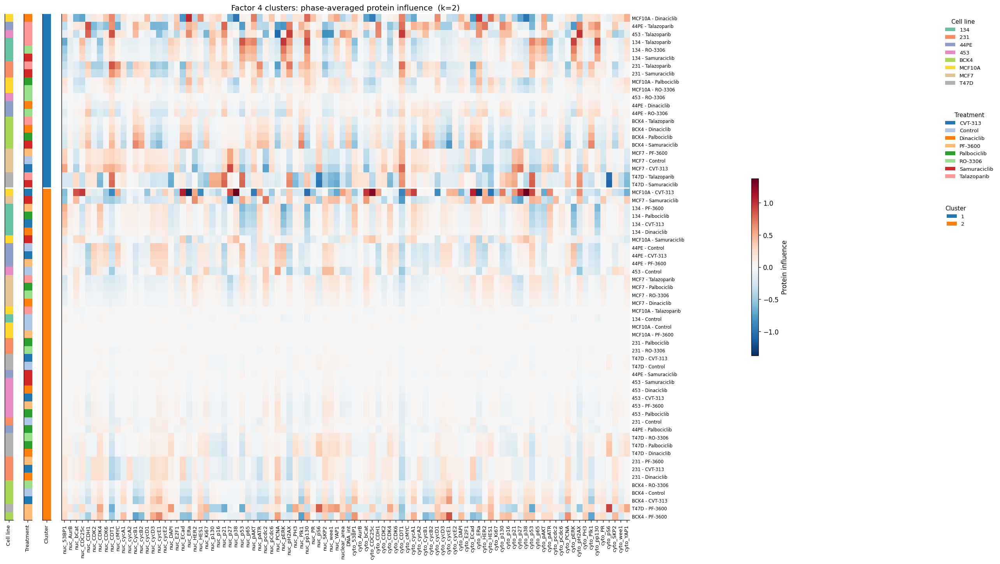

In [38]:
cross_cellline_cluster_heatmap(
    protein_factor_by_treatment_df.xs("Factor 4", level="factor"), labels_f4,
    title="Factor 4 clusters: phase-averaged protein influence",
);

## 6. Treatment factors across cell lines:

Each cell line's fit also re-expresses its 8 drugs as 8 treatment factors (weighted contrasts of the drugs); a treatment factor's signature is the matching weighted combination of the drugs' average protein profiles. The contrasts are defined separately in each line, so treatment factor $s$ in one line need not match treatment factor $s$ in another.

1. For each $\ell$: $\bar{\mathcal{G}}^{(\ell)} \leftarrow \frac{1}{c} \sum_j \big(\mathcal{G}^{(\ell)} \times_2 C^{(\ell)}\big)_{:,j,:} \in \mathbb{R}^{8 \times p_F}$ (row $s$ = treatment factor $s$).
2. For each $(\ell, s)$: row $\mathbf{w}_{\ell s} \leftarrow \bar{\mathcal{G}}^{(\ell)}_{s,:}\, P^{(\ell)\top} \in \mathbb{R}^{p}$.
3. $W \leftarrow$ all rows ($64 \times 96$).

Equivalently $\bar{\mathcal{G}}^{(\ell)} = T^{(\ell)\top} \bar{\mathcal{F}}^{(\ell)}$; the sign of $T^{(\ell)}_{:,s}$ is arbitrary.

In [39]:
treatment_factor_df = cross_cellline_treatment_factors(cct_dict)
print(f"Treatment factor matrix: {treatment_factor_df.shape}")
treatment_factor_df.head(8)

Treatment factor matrix: (64, 96)


nuc_53BP1  nuc_AurB  nuc_bCat  nuc_CDC25c  nuc_CDH1  \
cell_line factor                                                          
134       Factor 1   1.385475  0.602162  1.942226    1.539846  0.790364   
          Factor 2   1.109128  0.254947  1.157297    0.790561  0.446511   
          Factor 3  -1.344344  0.212846 -0.768300   -0.449845  0.010655   
          Factor 4  -1.238057  0.388713  0.109893    0.836120 -0.047860   
          Factor 5   0.319048 -0.057559  0.000570   -0.185025  0.027689   
          Factor 6  -0.180000 -0.033899 -0.003560    0.135908 -0.061971   
          Factor 7  -0.032938 -0.109644 -0.004420    0.069938 -0.075826   
          Factor 8  -0.011103  0.063647 -0.018953   -0.047417  0.031856   

                    nuc_CDK2  nuc_CDK4  nuc_CDK6  nuc_CDT1  nuc_cMYC  ...  \
cell_line factor                                                      ...   
134       Factor 1  0.933662  1.455686  2.059465  0.892140  1.250070  ...   
          Factor 2  0.465352  1.075635  1.199085  0.540415  0.728255  ...   
          Factor 3 -0.066603 -0.878844 -0.487486 -0.697127  0.545936  ...   
          Factor 4  0.438152 -1.113839  0.043542  0.267443 -0.662694  ...   
          Factor 5 -0.071572  0.268951 -0.017884 -0.066679  0.083016  ...   
          Factor 6 -0.000179 -0.163184  0.022751  0.104262 -0.056513  ...   
          Factor 7 -0.065283 -0.033954  0.040886  0.116223  0.027258  ...   
          Factor 8  0.034867 -0.016955 -0.056493 -0.073286 -0.066175  ...   

                    cyto_pERK  cyto_pH2AX  cyto_PH3  cyto_Plk1  cyto_pp130  \
cell_line factor                                                             
134       Factor 1   1.121980    2.019756  0.945246   0.533840    1.538739   
          Factor 2   0.267313    1.014903  0.381068   0.230599    0.576874   
          Factor 3   0.765027    0.462835  1.147347   0.174810    0.877013   
          Factor 4   1.858717    0.392996  0.078867   0.324412    1.231505   
          Factor 5  -0.448237   -0.129091 -0.046098  -0.042300   -0.342113   
          Factor 6   0.256177    0.051202 -0.066726  -0.040401    0.205422   
          Factor 7   0.059612    0.014164 -0.114611  -0.108399    0.089818   
          Factor 8  -0.030114   -0.046966  0.036998   0.063347   -0.073800   

                     cyto_PR  cyto_pS6  cyto_SKP2  cyto_wee1  cyto_YAP1  
cell_line factor                                                         
134       Factor 1  2.044776  0.942106   1.026413   0.894667   0.940423  
          Factor 2  1.123469  0.380111   0.492219   0.389119   0.542116  
          Factor 3  0.514301  0.926093   0.117914   0.886391  -1.198564  
          Factor 4 -0.303375  0.252983   0.460292   0.040349   0.852113  
          Factor 5  0.035394 -0.081802  -0.081766  -0.022054  -0.139102  
          Factor 6 -0.082112 -0.023708  -0.006652  -0.076903   0.126915  
          Factor 7 -0.062289 -0.079531  -0.079530  -0.120162   0.059852  
          Factor 8 -0.015549  0.022474   0.039508   0.045119  -0.016162  

[8 rows x 96 columns]

### 6.1 PCA:

Each point is one treatment factor from one cell line, placed so that similar protein signatures sit close together.

1. $Z \leftarrow \mathrm{PCA}_2(W)$.
2. Scatter $Z$, one point per $(\ell, s)$: color $= s$, marker $= \ell$.

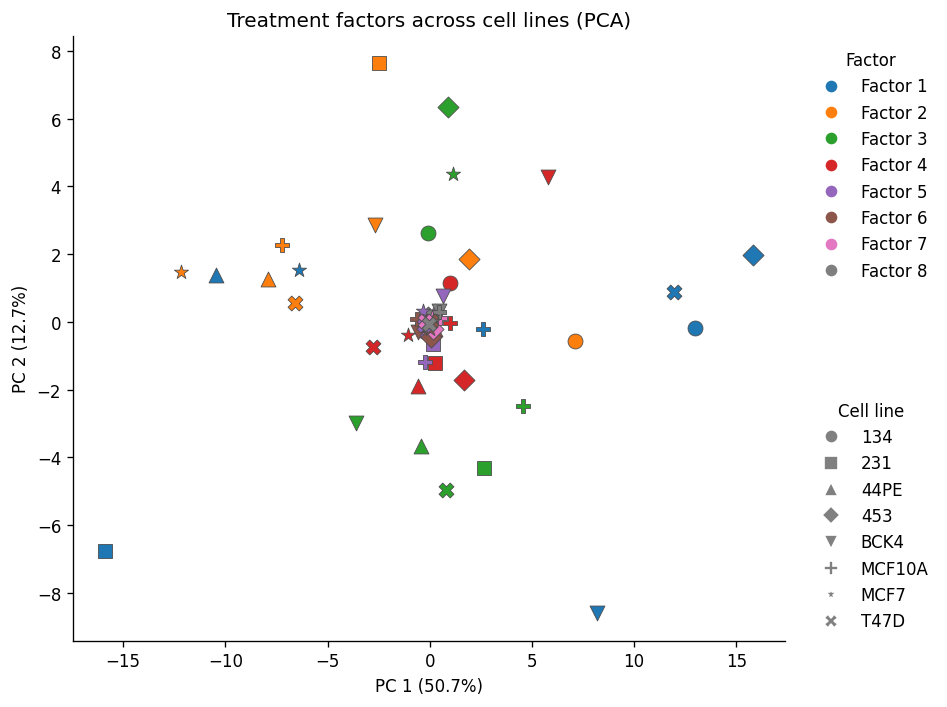

In [40]:
cross_cellline_embedding(
    treatment_factor_df, method="pca",
    title="Treatment factors across cell lines (PCA)"
);

### 6.2 t-SNE:

The same comparison with a nonlinear map that emphasizes local groups.

As 6.1 with $Z \leftarrow \mathrm{tSNE}_2(W)$.

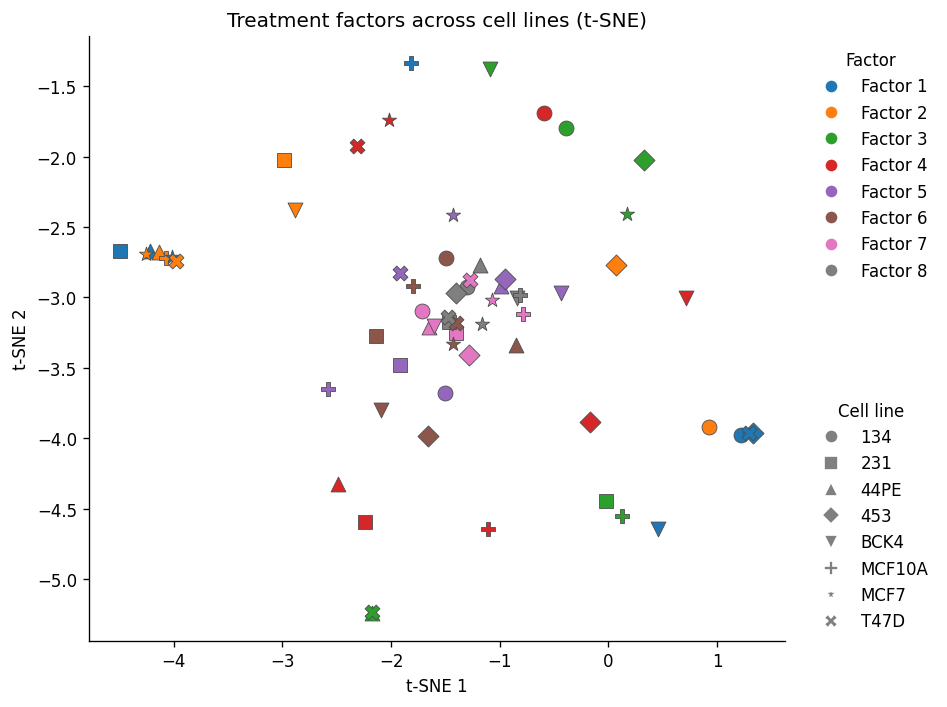

In [41]:
cross_cellline_embedding(
    treatment_factor_df, method="tsne",
    title="Treatment factors across cell lines (t-SNE)"
);

### 6.3 UMAP:

The same comparison with UMAP; tight groups are meaningful, distances between groups are not.

As 6.1 with $Z \leftarrow \mathrm{UMAP}_2(W)$.

/Users/kaiwycik/.pyenv/versions/3.13.3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


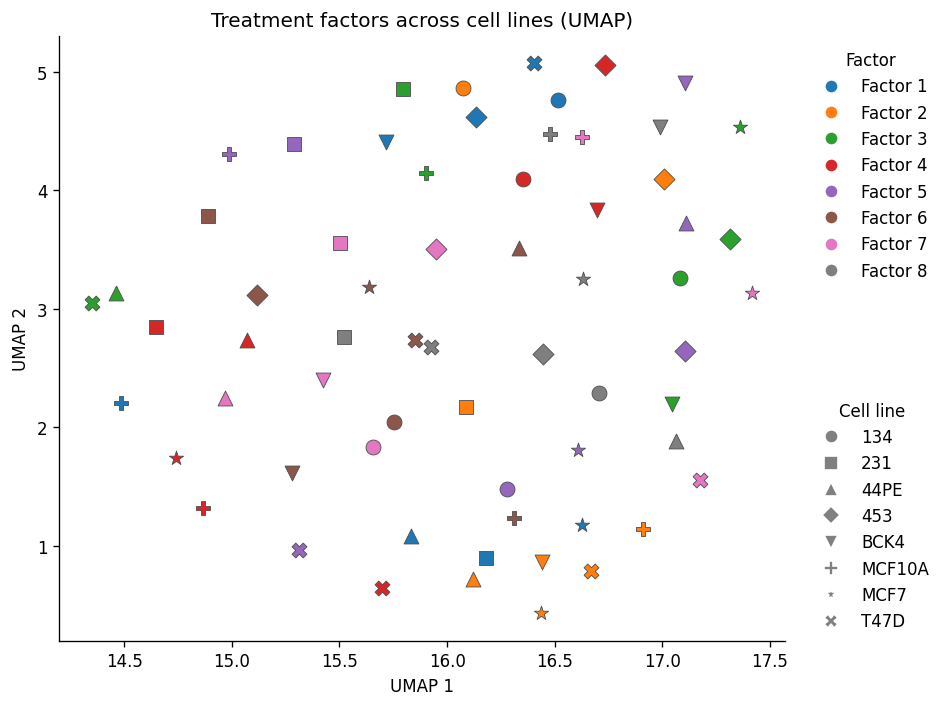

In [42]:
cross_cellline_embedding(
    treatment_factor_df, method="umap",
    title="Treatment factors across cell lines (UMAP)"
);

### 6.4 Cosine-similarity clustermap:

Similarity of the treatment-factor signatures, as in 2.3. The sign of a treatment factor is arbitrary, so a strongly negative similarity (blue) indicates the same signature as a strongly positive one (red).

As 2.3 on the rows of $W$; side bars: cell line, treatment factor $s$.

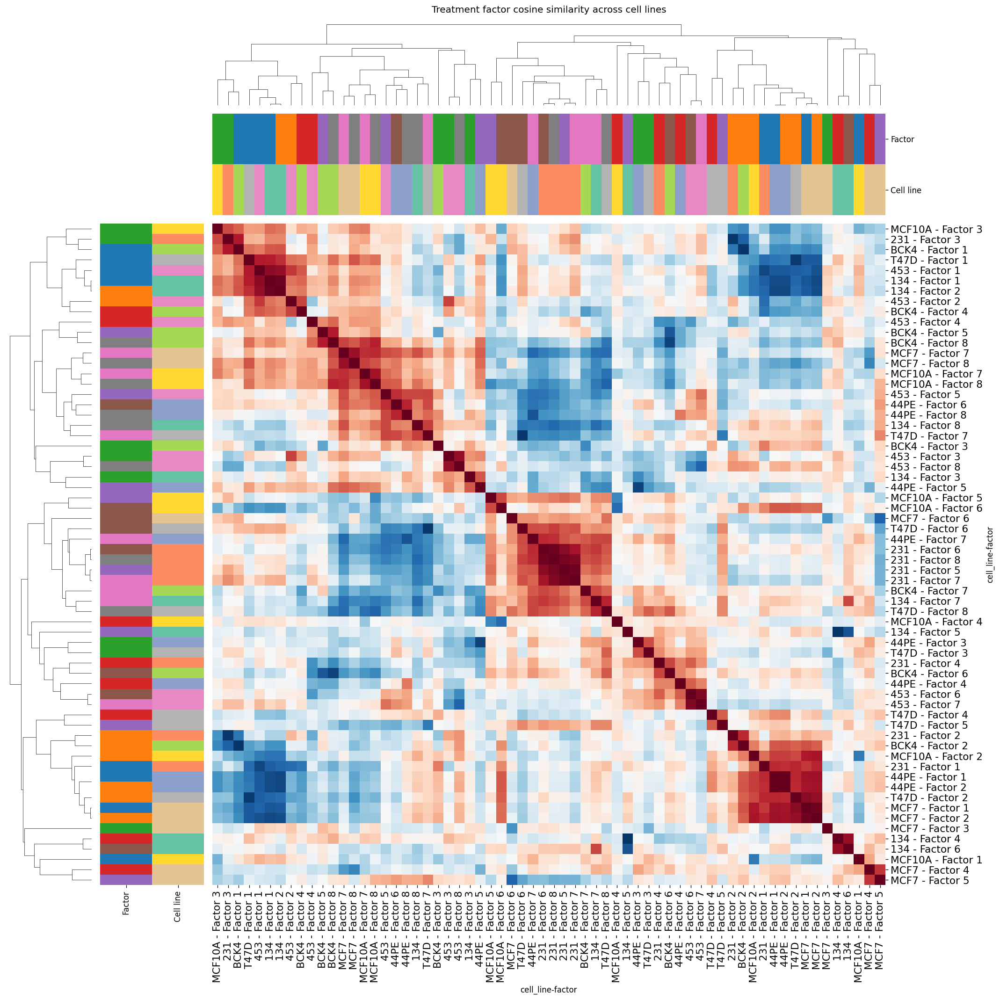

In [43]:
cross_cellline_clustermap(
    treatment_factor_df, annotate=False,
    title="Treatment factor cosine similarity across cell lines"
);

---